# 05 · Merge, labelling and classification

Merges V4 and III features per segment, assigns the 3 classes (0 Sain, 1 angine, 2 infactus), balances classes, compares SVM and KNN with grid search, and trains the final SVM (C=60, gamma=0.01) exported as `svm_model_C60_gamma001.pkl`.

> Originally run on Google Colab; saved outputs are kept. Set the paths below to rerun locally.

In [ ]:
# Paths — put the PhysioNet zip files in DATA_DIR (see ../data/README.md)
import os
import pandas as pd

DATA_DIR = "../data/raw"        # ptb-diagnostic-ecg-database-1.0.0.zip, european-st-t-database-1.0.0.zip
WORK_DIR = "../data/work"       # extracted records and intermediate CSVs
LABELS_CSV = "../data/labels.csv"
os.makedirs(WORK_DIR, exist_ok=True)


def load_patient_labels():
    """Diagnosis of each ischemic patient (replaces the original data2.csv)."""
    df = pd.read_csv(LABELS_CSV)
    df = df[df.label > 0]
    return pd.DataFrame({"ID patient ": df.record, "label": df.label_name})


In [2]:
import pandas as pd

# Load both feature CSV files
df_v4 = pd.read_csv(f"{WORK_DIR}/fV4.csv")
df_d3 = pd.read_csv(f"{WORK_DIR}/fd3.csv")

# Assume columns: filename, segment_index, f1, f2, ..., fN, label
# Rename feature columns with postfix
feature_cols_v4 = [col for col in df_v4.columns if col not in ['filename', 'segment_index', 'label']]
feature_cols_d3 = [col for col in df_d3.columns if col not in ['filename', 'segment_index', 'label']]

df_v4.rename(columns={col: f"{col}_v4" for col in feature_cols_v4}, inplace=True)
df_d3.rename(columns={col: f"{col}_d3" for col in feature_cols_d3}, inplace=True)

# Merge on filename and segment_index
merged = pd.merge(df_v4, df_d3, on=['filename', 'segment_index'])

# Optional: check for mismatch
group_v4 = df_v4.groupby('filename')['segment_index'].nunique()
group_d3 = df_d3.groupby('filename')['segment_index'].nunique()
mismatch = group_v4[group_v4 != group_d3]
if not mismatch.empty:
    print("⚠️ Files with mismatched segment counts:")
    print(mismatch)

# Save merged result
merged.to_csv(f"{WORK_DIR}/merged_features.csv", index=False)


In [3]:
merged.columns

Index(['filename', 'segment_index', 'label_x', 'A_max_v4', 'A_min_v4',
       'mean_v4', 'std_v4', 'rms_v4', 'kurtosis_v4', 'skewness_v4',
       'sample_entropy_v4', 'permutation_entropy_v4', 'approximate_entropy_v4',
       'label_y', 'A_max_d3', 'A_min_d3', 'mean_d3', 'std_d3', 'rms_d3',
       'kurtosis_d3', 'skewness_d3', 'sample_entropy_d3',
       'permutation_entropy_d3', 'approximate_entropy_d3'],
      dtype='object')

In [4]:
import pandas as pd


In [5]:
labels_df = load_patient_labels()
labels_df.columns

Index(['ID patient ', 'label'], dtype='object')

In [6]:
labels_df

,ID patient,label
0,e0103,Angine
1,e0104,infactus
2,e0105,infactus
3,e0107,Angine
4,e0108,infactus
5,e0111,Angine
6,e0112,Angine
7,e0113,Angine
8,e0114,Angine
9,e0136,Angine


In [7]:
import pandas as pd

# Load files
labels_df = load_patient_labels()

# Clean ID and labels
labels_df['ID patient '] = labels_df['ID patient '].str.strip()
labels_df['label'] = labels_df['label'].str.strip().str.lower()
merged['patient_id'] = merged['filename'].str.extract(r'^(e\d+)', expand=False)

# Build patient-to-label map
label_map = dict(zip(labels_df['ID patient '], labels_df['label']))

# Only update labels where current label == 1 and patient is in label_map
merged['label'] = merged.apply(
    lambda row: label_map[row['patient_id']] if row['label_x'] == 1 and row['patient_id'] in label_map else 0,
    axis=1
)

# Final label-to-number mapping (0 = no angina, others assigned incrementally)
unique_labels = sorted(set(val for val in label_map.values()))
label_to_num = {label: idx + 1 for idx, label in enumerate(unique_labels)}  # Start at 1
label_to_num["Sain"] = 0  # Manually set 0

# Replace string labels with numbers
merged['label'] = merged['label'].apply(lambda x: label_to_num.get(x, x))

# Drop temp column
merged.drop(columns=['patient_id'], inplace=True)

# Save
merged.to_csv(f"{WORK_DIR}/merged_features_updated.csv", index=False)

# Print final mapping
print("Label to number mapping:")
print(label_to_num)


Label to number mapping:
{'angine': 1, 'infactus': 2, 'Sain': 0}


In [8]:
import pandas as pd

merged=pd.read_csv(f"{WORK_DIR}/merged_features_updated.csv")
merged

,filename,segment_index,label_x,A_max_v4,A_min_v4,mean_v4,std_v4,rms_v4,kurtosis_v4,skewness_v4,...,A_min_d3,mean_d3,std_d3,rms_d3,kurtosis_d3,skewness_d3,sample_entropy_d3,permutation_entropy_d3,approximate_entropy_d3,label
0,e0159,0,1,0.806109,-0.717719,-0.005236,0.137129,0.137229,16.784170,0.488478,...,-0.246613,0.003549,0.149006,0.149048,8.699983,2.487626,0.256266,0.921144,0.356419,2
1,e0159,1,1,0.804569,-0.784780,0.003577,0.139744,0.139790,17.264280,-0.239560,...,-0.255141,-0.003099,0.157143,0.157174,9.475962,2.594186,0.312909,0.868419,0.383249,2
2,e0159,2,1,0.833826,-0.761184,-0.005253,0.140956,0.141054,17.506569,-0.013856,...,-0.212388,0.003184,0.149810,0.149844,9.777524,2.661925,0.368154,0.873312,0.449760,2
3,e0159,3,1,0.859387,-0.746722,0.007052,0.149404,0.149570,16.183099,0.614808,...,-0.242974,0.002112,0.150754,0.150768,7.619384,2.393307,0.311998,0.908495,0.415553,2
4,e0159,4,1,0.912980,-0.606819,-0.002567,0.143168,0.143191,16.786573,1.593946,...,-0.332382,-0.000757,0.148522,0.148524,9.168910,2.320361,0.281453,0.942775,0.379005,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23939,s0311lre,158,0,1.200074,-0.677763,0.001402,0.195217,0.195222,18.759496,3.108694,...,-0.610775,-0.001876,0.108511,0.108527,16.983391,-3.875083,0.032684,0.603303,0.071238,0
23940,s0311lre,159,0,1.192243,-0.660817,-0.002272,0.191516,0.191530,19.370063,3.195762,...,-0.541381,0.002225,0.095961,0.095987,18.144120,-3.948544,0.037941,0.584803,0.068399,0
23941,s0311lre,160,0,1.200505,-0.643563,0.004113,0.200489,0.200531,18.606820,3.322343,...,-0.532475,-0.002781,0.099532,0.099571,14.867234,-3.454512,0.034177,0.609315,0.065376,0
23942,s0311lre,161,0,1.199861,-0.673176,-0.012288,0.196246,0.196631,19.520782,3.317416,...,-0.583665,0.008263,0.104951,0.105276,16.885550,-3.799711,0.037232,0.596165,0.065010,0


In [9]:
merged.label.value_counts()

,count
label,
0,10422
2,7347
1,6175


In [10]:
merged.columns

Index(['filename', 'segment_index', 'label_x', 'A_max_v4', 'A_min_v4',
       'mean_v4', 'std_v4', 'rms_v4', 'kurtosis_v4', 'skewness_v4',
       'sample_entropy_v4', 'permutation_entropy_v4', 'approximate_entropy_v4',
       'label_y', 'A_max_d3', 'A_min_d3', 'mean_d3', 'std_d3', 'rms_d3',
       'kurtosis_d3', 'skewness_d3', 'sample_entropy_d3',
       'permutation_entropy_d3', 'approximate_entropy_d3', 'label'],
      dtype='object')

In [11]:
##################################### Calcul Histogramme ################################

In [12]:
import pandas as pd

label_map = {0: 'sains', 1: 'angine', 2: 'infactus'}

# Define base names of features
linear_features = ['A_max', 'A_min', 'mean', 'std', 'rms', 'kurtosis', 'skewness']
nonlinear_features = ['sample_entropy', 'permutation_entropy', 'approximate_entropy']

# Helper function to extract columns with given suffix
def extract_cols(features, suffix):
    return [f"{feat}_{suffix}" for feat in features]

# Get columns by group
linear_v4_cols = extract_cols(linear_features, "v4")
linear_d3_cols = extract_cols(linear_features, "d3")
nonlinear_v4_cols = extract_cols(nonlinear_features, "v4")
nonlinear_d3_cols = extract_cols(nonlinear_features, "d3")

# Add label column for grouping
df_linear_v4 = merged[linear_v4_cols + ['label']]
df_linear_d3 = merged[linear_d3_cols + ['label']]
df_nonlinear_v4 = merged[nonlinear_v4_cols + ['label']]
df_nonlinear_d3 = merged[nonlinear_d3_cols + ['label']]

def format_num(x, decimals=7):
    """Format number as fixed-point decimal with given decimals, no scientific notation"""
    return f"{x:.{decimals}f}"

def get_formatted_stats(df):
    stats = df.groupby('label').agg(['mean', 'std'])
    stats.index = stats.index.map(label_map)

    formatted_df = pd.DataFrame(index=stats.index)

    for feature in stats.columns.levels[0]:  # feature names are level 0
        mean_vals = stats[(feature, 'mean')]
        std_vals = stats[(feature, 'std')]

        formatted_vals = mean_vals.apply(lambda x: f"{x:.9f}") + " ± " + std_vals.apply(lambda x: f"{x:.9f}")
        formatted_df[feature] = formatted_vals

    return formatted_df



# Get results
linear_v4_stats = get_formatted_stats(df_linear_v4)
linear_d3_stats = get_formatted_stats(df_linear_d3)
nonlinear_v4_stats = get_formatted_stats(df_nonlinear_v4)
nonlinear_d3_stats = get_formatted_stats(df_nonlinear_d3)

# Display results
print("🔷 Linear V4 Parameters (Mean ± SD):\n\n\n")
display(linear_v4_stats)
print("\n\n\n\n----------------------------------------------------------\n\n\n\n")

print("🔷 Linear D3 Parameters (Mean ± SD):\n\n\n")
display(linear_d3_stats)
print("\n\n\n\n----------------------------------------------------------\n\n\n\n")

print("🔷 Nonlinear V4 Parameters (Mean ± SD):\n\n\n")
display(nonlinear_v4_stats)
print("\n\n\n\n----------------------------------------------------------\n\n\n\n")

print("🔷 Nonlinear D3 Parameters (Mean ± SD):\n\n\n")
display(nonlinear_d3_stats)


🔷 Linear V4 Parameters (Mean ± SD):





,A_max_v4,A_min_v4,mean_v4,std_v4,rms_v4,kurtosis_v4,skewness_v4
label,,,,,,,
sains,1.189247127 ± 0.553647914,-0.846129579 ± 0.395797988,0.000069914 ± 0.007835531,0.262707265 ± 0.080888574,0.262806928 ± 0.080944316,9.086829768 ± 6.073114046,1.275438343 ± 1.771736075
angine,1.299399775 ± 0.333309823,-0.498742417 ± 0.262635864,0.000083701 ± 0.025868917,0.236247585 ± 0.073279880,0.236600392 ± 0.076630916,16.241569724 ± 8.687806752,3.285478838 ± 1.340080369
infactus,1.352213692 ± 0.269518621,-0.527638204 ± 0.275035079,0.000006192 ± 0.005369097,0.221272425 ± 0.045661681,0.221339846 ± 0.045650529,17.918098235 ± 5.184696118,3.264789452 ± 1.064652526






----------------------------------------------------------




🔷 Linear D3 Parameters (Mean ± SD):





,A_max_d3,A_min_d3,mean_d3,std_d3,rms_d3,kurtosis_d3,skewness_d3
label,,,,,,,
sains,0.584090440 ± 0.500674731,-0.245358083 ± 0.179384832,0.000000021 ± 0.005821772,0.097216169 ± 0.063870695,0.097401848 ± 0.063853103,20.126603440 ± 10.484753997,1.819896521 ± 3.397189255
angine,0.500208309 ± 0.331464614,-0.408810759 ± 0.353273524,-0.000036455 ± 0.015669370,0.125318755 ± 0.110121082,0.125566694 ± 0.110950299,14.082408168 ± 11.234278258,0.366518536 ± 3.214073491
infactus,0.600986628 ± 0.445197769,-0.388656182 ± 0.303650027,0.000008196 ± 0.008931270,0.134965545 ± 0.090192859,0.135173374 ± 0.090323691,6.554327976 ± 5.550666314,1.257323794 ± 1.093278652






----------------------------------------------------------




🔷 Nonlinear V4 Parameters (Mean ± SD):





,sample_entropy_v4,permutation_entropy_v4,approximate_entropy_v4
label,,,
sains,0.028208422 ± 0.044433678,0.560054422 ± 0.021161698,0.067977518 ± 0.051112926
angine,0.109595934 ± 0.063747613,0.864903174 ± 0.058494353,0.151512095 ± 0.064388866
infactus,0.122287346 ± 0.072189694,0.863790248 ± 0.048705097,0.142459581 ± 0.075648046






----------------------------------------------------------




🔷 Nonlinear D3 Parameters (Mean ± SD):





,sample_entropy_d3,permutation_entropy_d3,approximate_entropy_d3
label,,,
sains,0.061296214 ± 0.041456772,0.608320278 ± 0.023180388,0.104668321 ± 0.052294623
angine,0.292534810 ± 0.154922423,0.909939049 ± 0.039613072,0.344592231 ± 0.138514705
infactus,0.332810467 ± 0.177759216,0.883677185 ± 0.043470749,0.376083353 ± 0.159573579


/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 128998 (\N{LARGE BLUE SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128998 (\N{LARGE BLUE SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


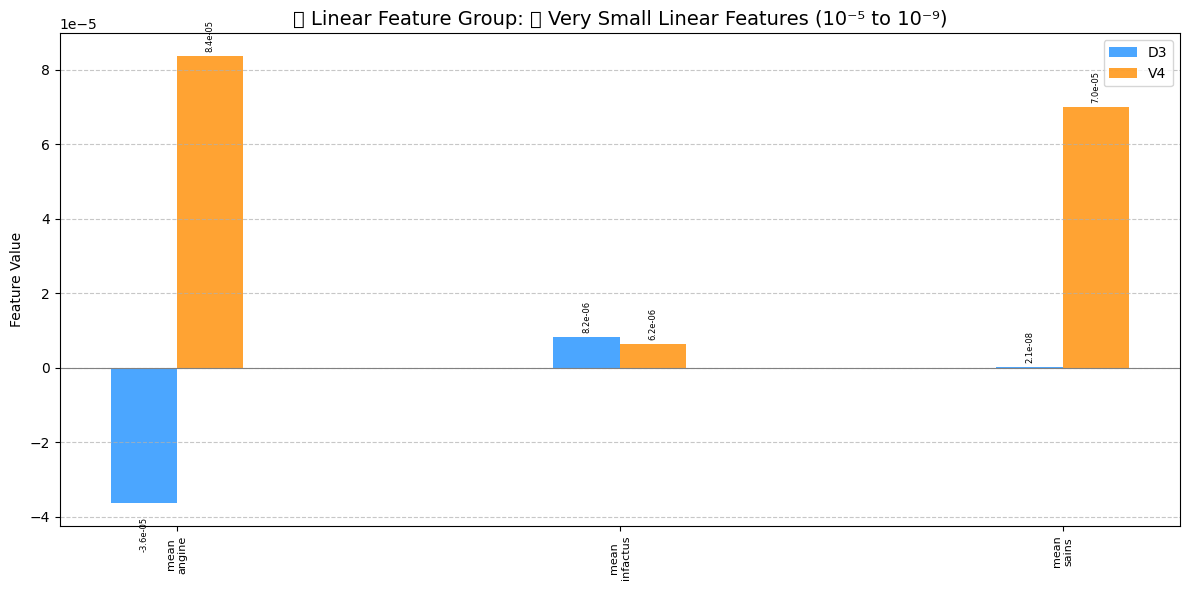

/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


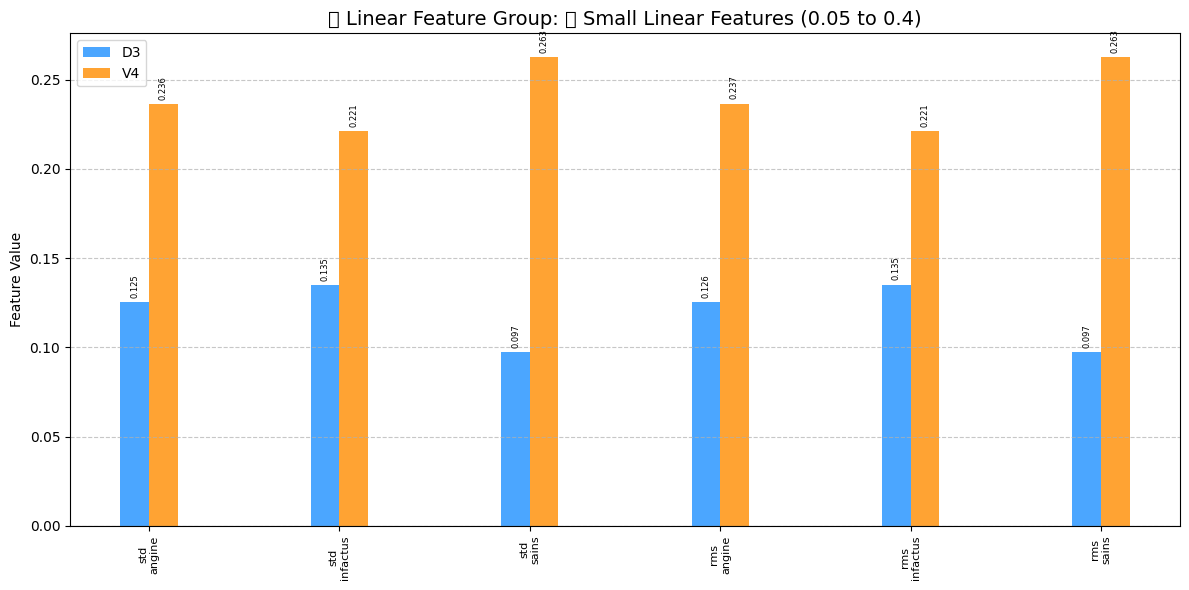

/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 129001 (\N{LARGE GREEN SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129001 (\N{LARGE GREEN SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


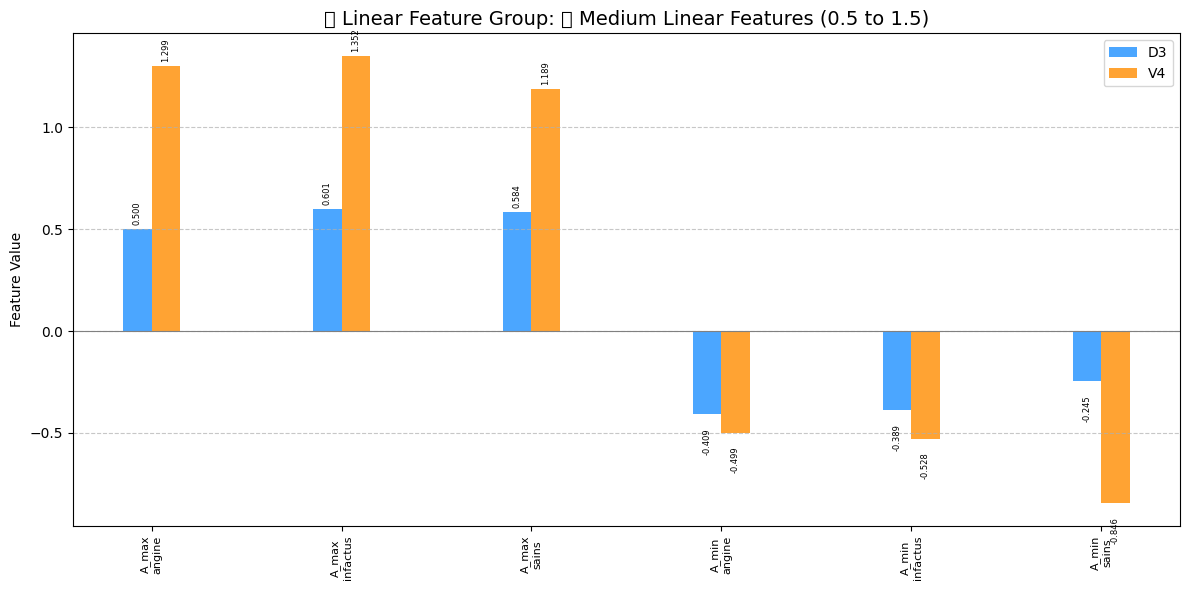

/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 128997 (\N{LARGE RED SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128997 (\N{LARGE RED SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


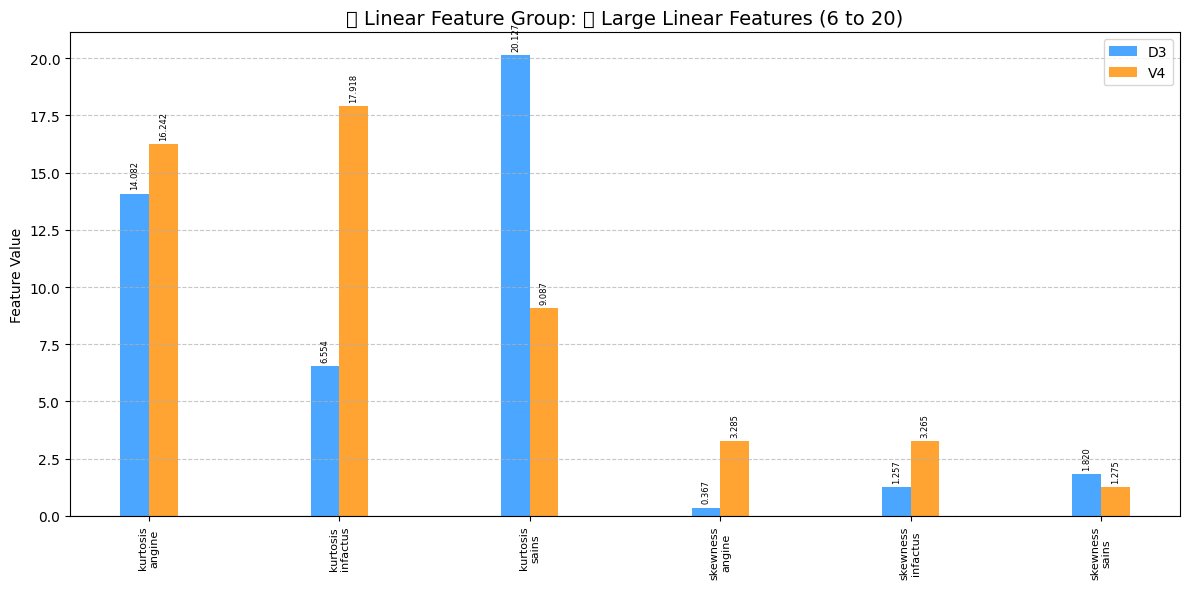

/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 128998 (\N{LARGE BLUE SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128998 (\N{LARGE BLUE SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


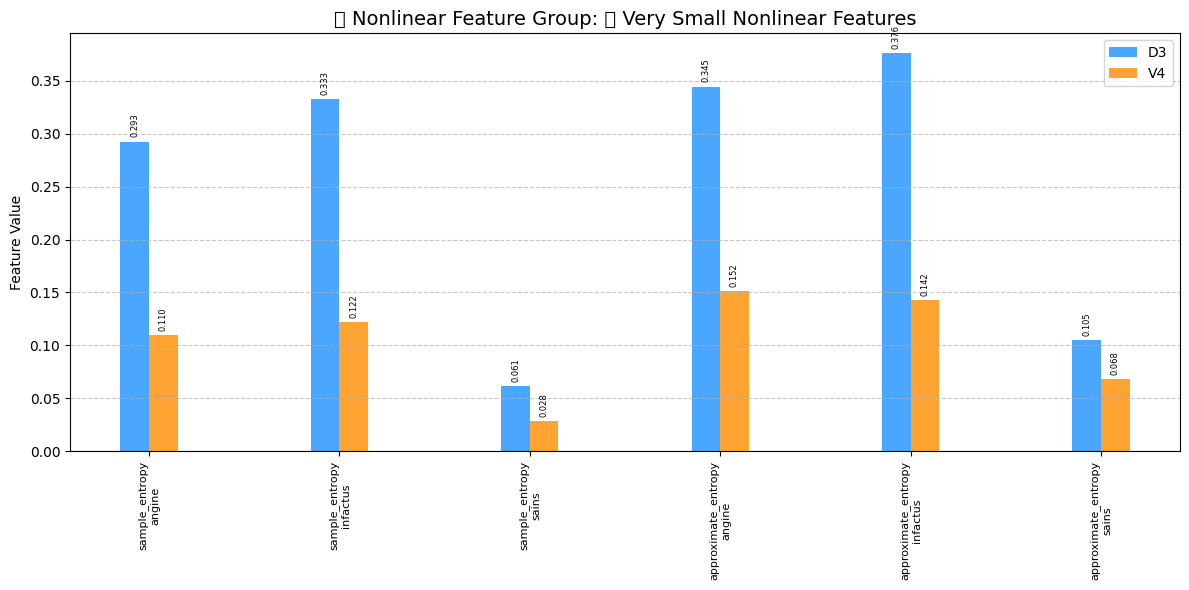

/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-13-105854119.py:53: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


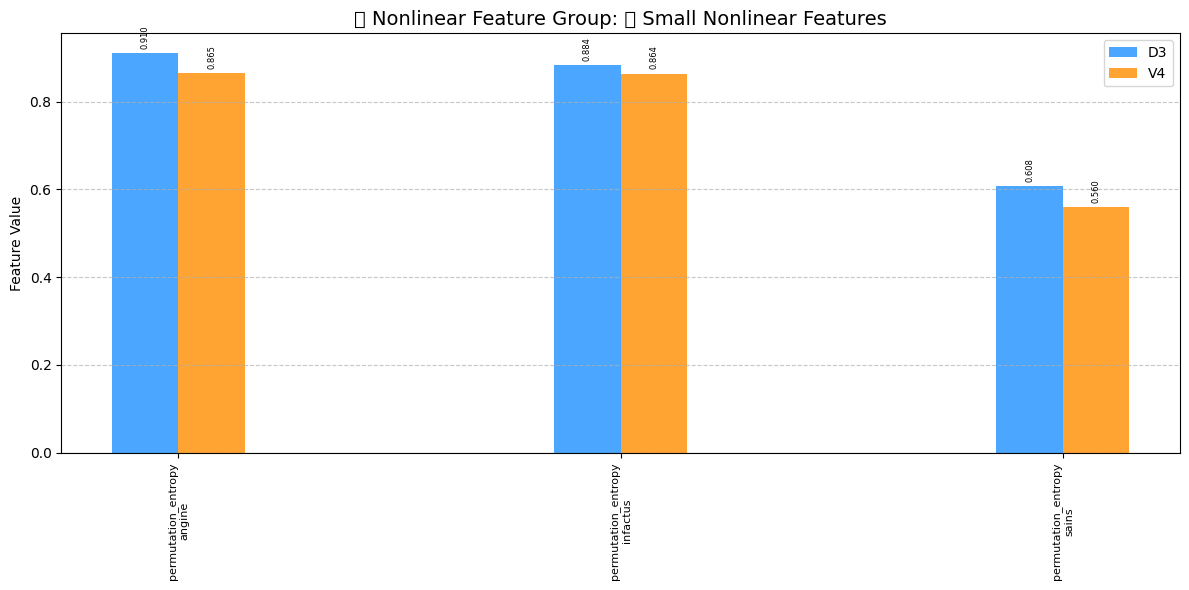

In [13]:
import matplotlib.pyplot as plt
import numpy as np
# Define feature lists
linear_features = ['A_max', 'A_min', 'mean', 'std', 'rms', 'kurtosis', 'skewness']
nonlinear_features = ['sample_entropy', 'permutation_entropy', 'approximate_entropy']

# Map label to class names
label_map = {0: 'sains', 1: 'angine', 2: 'infactus'}

# Choose one class to compare (e.g., all)
data = merged.copy()
data['label_name'] = data['label'].map(label_map)

# Group by class name and compute mean
grouped = data.groupby('label_name').mean(numeric_only=True)
def plot_grouped_features(data_grouped, feature_groups, title_prefix=""):
    for group_title, features in feature_groups.items():
        labels = []
        d3_vals = []
        v4_vals = []

        for feat in features:
            for cls in data_grouped.index:
                labels.append(f"{feat}\n{cls}")
                d3_vals.append(data_grouped.loc[cls, f"{feat}_d3"])
                v4_vals.append(data_grouped.loc[cls, f"{feat}_v4"])

        x = np.arange(len(labels))
        width = 0.15

        fig, ax = plt.subplots(figsize=(max(12, len(labels) * 0.5), 6))
        bars1 = ax.bar(x - width/2, d3_vals, width=width, label='D3', color='dodgerblue', alpha=0.8)
        bars2 = ax.bar(x + width/2, v4_vals, width=width, label='V4', color='darkorange', alpha=0.8)

        ax.set_title(f"{title_prefix} {group_title}", fontsize=14)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=90, ha='center', fontsize=8)
        ax.set_ylabel("Feature Value")
        ax.axhline(0, color='gray', linewidth=0.8)
        ax.grid(axis='y', linestyle='--', alpha=0.7)
        ax.legend()

        # Add value labels on top of bars
        for bar in bars1 + bars2:
            height = bar.get_height()
            ax.annotate(f'{height:.1e}' if abs(height) < 0.01 else f'{height:.3f}',
                        xy=(bar.get_x() + bar.get_width() / 2, height),
                        xytext=(0, 3 if height >= 0 else -10),
                        textcoords="offset points",
                        ha='center', va='bottom' if height >= 0 else 'top',
                        fontsize=6, rotation=90)

        plt.tight_layout()
        plt.show()

# Define your grouped features by scale
linear_groups = {
    "🟦 Very Small Linear Features (10⁻⁵ to 10⁻⁹)": ["mean"],
    "🟨 Small Linear Features (0.05 to 0.4)": ["std", "rms"],
    "🟩 Medium Linear Features (0.5 to 1.5)": ["A_max", "A_min"],
    "🟥 Large Linear Features (6 to 20)": ["kurtosis", "skewness"]
}

nonlinear_groups = {
    "🟦 Very Small Nonlinear Features": ["sample_entropy", "approximate_entropy"],
    "🟨 Small Nonlinear Features": ["permutation_entropy"]
}

# Example usage:
# `grouped` should be your DataFrame where rows are class labels (sains, angine, infarctus)
# and columns are like 'A_max_d3', 'A_max_v4', etc.

# Plot all
plot_grouped_features(grouped, linear_groups, title_prefix="📊 Linear Feature Group:")
plot_grouped_features(grouped, nonlinear_groups, title_prefix="📊 Nonlinear Feature Group:")


/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 128998 (\N{LARGE BLUE SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128998 (\N{LARGE BLUE SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


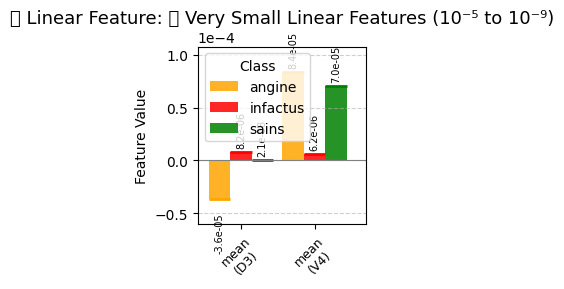

/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


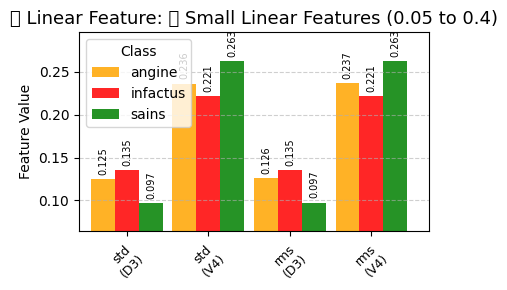

/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 129001 (\N{LARGE GREEN SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129001 (\N{LARGE GREEN SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


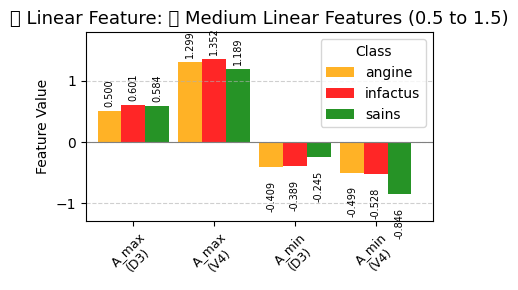

/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 128997 (\N{LARGE RED SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128997 (\N{LARGE RED SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


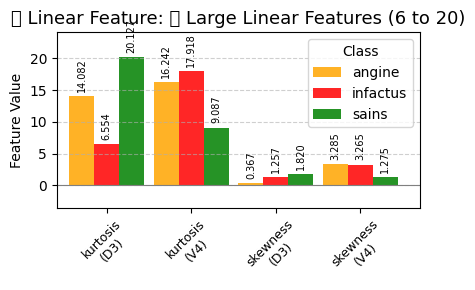

/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 128998 (\N{LARGE BLUE SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128998 (\N{LARGE BLUE SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


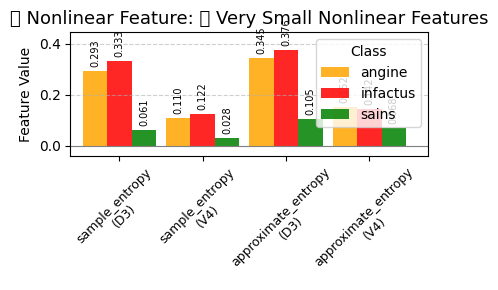

/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipython-input-14-998864450.py:124: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 129000 (\N{LARGE YELLOW SQUARE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


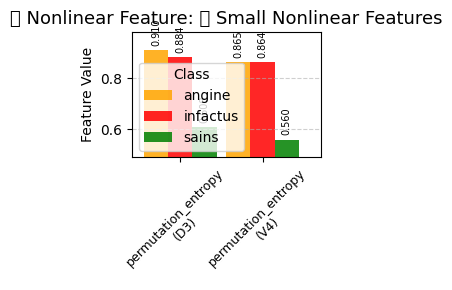

In [14]:
import matplotlib.pyplot as plt
import numpy as np
# Define feature lists
linear_features = ['A_max', 'A_min', 'mean', 'std', 'rms', 'kurtosis', 'skewness']
nonlinear_features = ['sample_entropy', 'permutation_entropy', 'approximate_entropy']

# Map label to class names
label_map = {0: 'sains', 1: 'angine', 2: 'infactus'}

# Choose one class to compare (e.g., all)
data = merged.copy()
data['label_name'] = data['label'].map(label_map)

# Group by class name and compute mean
grouped = data.groupby('label_name').mean(numeric_only=True)
def plot_d3_v4_comparison_by_feature(data_grouped, feature_groups, title_prefix=""):
    import matplotlib.pyplot as plt
    import numpy as np

    class_colors = {
        'sains': 'green',
        'angine': 'orange',
        'infactus': 'red'
    }
    classes = list(data_grouped.index)

    # Bar width fixed
    bar_width = 0.25
    fixed_fig_height = 3

    for group_title, features in feature_groups.items():
        n_features = len(features)
        n_versions = 2  # d3 and v4
        n_classes = len(classes)

        total_groups = n_features * n_versions  # number of feature-version groups

        # Space between groups
        space_between_groups = 0.1

        # Width per group (bars + space)
        group_width = bar_width * n_classes + space_between_groups

        # Total number of bars in all groups
        total_bars = total_groups * n_classes

        # Calculate total figure width to keep bar width constant
        # Add some margin (e.g. 1 inch) so bars and labels fit nicely
        fixed_fig_width = total_bars * bar_width + total_groups * space_between_groups + 1

        # X positions for groups (feature-version combos)
        x = np.arange(total_groups) * group_width

        fig, ax = plt.subplots(figsize=(fixed_fig_width, fixed_fig_height))

        added_labels = set()

        for i, cls in enumerate(classes):
            heights = []
            for feat in features:
                for version in ['d3', 'v4']:
                    value = data_grouped.loc[cls, f"{feat}_{version}"]
                    heights.append(value)

            # Offset bars for this class inside each group
            offsets = x + i * bar_width

            label = cls if cls not in added_labels else None
            bars = ax.bar(offsets, heights, width=bar_width, color=class_colors[cls], label=label, alpha=0.85)
            added_labels.add(cls)

            for bar in bars:
                height = bar.get_height()
                ax.annotate(f'{height:.1e}' if abs(height) < 0.01 else f'{height:.3f}',
                            xy=(bar.get_x() + bar.get_width() / 2, height),
                            xytext=(0, 3 if height >= 0 else -10),
                            textcoords="offset points",
                            ha='center', va='bottom' if height >= 0 else 'top',
                            fontsize=7, rotation=90)

                very_small_threshold = 1e-4
                if abs(height) < very_small_threshold and height != 0:
                    ax.hlines(y=height, xmin=bar.get_x(), xmax=bar.get_x() + bar.get_width(),
                              colors=class_colors[cls], linewidth=2)

        xtick_labels = [f"{feat}\n({v.upper()})" for feat in features for v in ['d3', 'v4']]
        group_centers = x + (bar_width * n_classes) / 2 - (bar_width / 2)
        ax.set_xticks(group_centers)
        ax.set_xticklabels(xtick_labels, fontsize=9, rotation=45)

        all_vals = []
        mean_vals = []
        for feat in features:
            for version in ['d3', 'v4']:
                for cls in classes:
                    val = data_grouped.loc[cls, f"{feat}_{version}"]
                    all_vals.append(val)
                    if feat == "mean":
                        mean_vals.append(val)

        min_val = min(all_vals)
        max_val = max(all_vals)
        range_val = max_val - min_val

        margin = range_val * 0.2 if range_val > 0 else 1e-6
        ax.set_ylim(min_val - margin, max_val + margin)

        if mean_vals and max(abs(v) for v in mean_vals) < 1e-7:
            ax.ticklabel_format(axis='y', style='sci', scilimits=(-10, 10))
        else:
            if abs(max_val) < 1e-3:
                ax.ticklabel_format(axis='y', style='sci', scilimits=(-2, 2))

        ax.set_title(f"{title_prefix} {group_title}", fontsize=13)
        ax.set_ylabel("Feature Value")
        ax.axhline(0, color='gray', linewidth=0.8)
        ax.grid(axis='y', linestyle='--', alpha=0.6)
        ax.legend(title="Class")

        # Set x limits to cover all bars nicely
        total_width = total_groups * group_width
        ax.set_xlim(-bar_width, total_width)

        plt.tight_layout()
        plt.show()


# Define your grouped features by scale
linear_groups = {
    "🟦 Very Small Linear Features (10⁻⁵ to 10⁻⁹)": ["mean"],
    "🟨 Small Linear Features (0.05 to 0.4)": ["std", "rms"],
    "🟩 Medium Linear Features (0.5 to 1.5)": ["A_max", "A_min"],
    "🟥 Large Linear Features (6 to 20)": ["kurtosis", "skewness"]
}

nonlinear_groups = {
    "🟦 Very Small Nonlinear Features": ["sample_entropy", "approximate_entropy"],
    "🟨 Small Nonlinear Features": ["permutation_entropy"]
}

# Example usage:
# `grouped` should be your DataFrame where rows are class labels (sains, angine, infarctus)
# and columns are like 'A_max_d3', 'A_max_v4', etc.

# Plot all
plot_d3_v4_comparison_by_feature(grouped, linear_groups, title_prefix="📊 Linear Feature:")
plot_d3_v4_comparison_by_feature(grouped, nonlinear_groups, title_prefix="📊 Nonlinear Feature:")



In [15]:
max_per_class = merged.groupby('label').apply(lambda x: x.head(6170)).reset_index(drop=True)


/tmp/ipython-input-15-411827286.py:1: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  max_per_class = merged.groupby('label').apply(lambda x: x.head(6170)).reset_index(drop=True)


In [16]:
max_per_class.label.value_counts()

,count
label,
0,6170
1,6170
2,6170


In [27]:
from sklearn.feature_selection import f_classif, SelectKBest

# Separate features and labels
X = max_per_class.drop(columns=['filename', 'label',"label_x","label_y"])
y = max_per_class['label']

# Encode labels to numbers if not already
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_encoded = le.fit_transform(y)


# Get selected feature names
selected_features = X.columns
print("Selected features:", selected_features.tolist())


Selected features: ['segment_index', 'A_max_v4', 'A_min_v4', 'mean_v4', 'std_v4', 'rms_v4', 'kurtosis_v4', 'skewness_v4', 'sample_entropy_v4', 'permutation_entropy_v4', 'approximate_entropy_v4', 'A_max_d3', 'A_min_d3', 'mean_d3', 'std_d3', 'rms_d3', 'kurtosis_d3', 'skewness_d3', 'sample_entropy_d3', 'permutation_entropy_d3', 'approximate_entropy_d3']


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42)
import numpy as np
from collections import Counter

# Assuming y_train and y_test are numpy arrays or lists
train_counts = Counter(y_train)
test_counts = Counter(y_test)

# Map from encoded label to original class name
label_map = {0: 'no angina', 1: 'angine', 2: 'infactus'}

# Print counts nicely
print("Train set class distribution:")
for label, count in train_counts.items():
    print(f"{label_map[label]}: {count}")

print("\nTest set class distribution:")
for label, count in test_counts.items():
    print(f"{label_map[label]}: {count}")


Train set class distribution:
angine: 4298
no angina: 4342
infactus: 4317

Test set class distribution:
infactus: 1853
no angina: 1828
angine: 1872


In [23]:
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42)

# --- SVM with GridSearchCV ---
svm_params = {
    'C': [10, 20, 30, 40, 50, 60],
    'gamma': [0.01, 0.1, 0.5, 1, 2],
    'kernel': ['rbf']
}

svm_grid = GridSearchCV(SVC(), svm_params, cv=5, scoring='accuracy')
svm_grid.fit(X_train, y_train)

print("Best SVM Parameters:", svm_grid.best_params_)
y_pred_svm = svm_grid.predict(X_test)
print("SVM Classification Report:\n", classification_report(y_test, y_pred_svm))

# --- KNN with GridSearchCV ---
knn_params = {
    'n_neighbors': list(range(2, 21))
}

knn_grid = GridSearchCV(KNeighborsClassifier(), knn_params, cv=5, scoring='accuracy')
knn_grid.fit(X_train, y_train)

print("Best KNN Parameters:", knn_grid.best_params_)
y_pred_knn = knn_grid.predict(X_test)
print("KNN Classification Report:\n", classification_report(y_test, y_pred_knn))


KeyboardInterrupt: 

In [28]:
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix
import joblib

# Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, random_state=42)

# Train SVM with specific hyperparameters
svm_model = SVC(C=60, gamma=0.01, kernel='rbf')
svm_model.fit(X_train, y_train)

# Predict
y_pred = svm_model.predict(X_test)

# Evaluation
print("SVM Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Classification Report:\n", classification_report(y_test, y_pred))

# Save the model
joblib.dump(svm_model, 'svm_model_C60_gamma001.pkl')


SVM Accuracy: 0.9879344498469296
Confusion Matrix:
 [[1826    2    0]
 [   6 1846   20]
 [   0   39 1814]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      1828
           1       0.98      0.99      0.98      1872
           2       0.99      0.98      0.98      1853

    accuracy                           0.99      5553
   macro avg       0.99      0.99      0.99      5553
weighted avg       0.99      0.99      0.99      5553



['svm_model_C60_gamma001.pkl']

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
def plot_conf_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    labels = sorted(set(y_true))  # e.g., [0, 1, 2, 3]

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title(f'Confusion Matrix - {title}')
    plt.tight_layout()
    plt.show()

# Plot for SVM
plot_conf_matrix(y_test, y_pred_svm, "SVM")

# Plot for KNN
plot_conf_matrix(y_test, y_pred_knn, "KNN")